# 10 · Skill extraction: rules vs a learned tagger

A separate experiment from the matching ladder (proposal §4.3):

* **rules:** a longest-match phrase matcher over the committed vocabulary
  (`data/vocab/skills.csv`: ESCO ICT scope + `data_jobs` + the baseline's regex terms);
* **learned:** a MiniLM token classifier fine-tuned on SkillSpan train, early-stopped on
  validation.

Both are scored on **SkillSpan test** (job postings, 3,569 sentences) and **DataTurks**
(resumes). Only 20 DataTurks documents are in its test split, and 20 decide nothing, so
the record also scores all 220. CIs are bootstraps over sentences or documents. Deltas
are paired.

Read from `output/extraction/extraction-metrics.json`. The decision is D49
(`plan/2026-09-26-top-down-reset/08-extraction.md`).

In [1]:
import json

import matplotlib.pyplot as plt
import pandas as pd

from candidate_screener import reporting
from candidate_screener.config import OUTPUT

reporting.style(plt)
r = json.loads((OUTPUT / "extraction" / "extraction-metrics.json").read_text(encoding="utf-8"))
print(f"vocabulary: {r['vocab']['rows']} aliases -> {r['vocab']['canonicals']} canonical skills")

vocabulary: 9124 aliases -> 1691 canonical skills


## Span F1 by corpus

In [2]:
def row(corpus, block, system):
    b = block[system]
    return {"corpus": corpus, "system": system, "n": b["n_units"], "predicted": b["n_pred"], "gold": b["n_gold"],
            "strict F1": f"{b['strict']['f1']:.3f} [{b['strict']['f1_ci'][0]:.2f}, {b['strict']['f1_ci'][1]:.2f}]",
            "partial F1": f"{b['partial']['f1']:.3f} [{b['partial']['f1_ci'][0]:.2f}, {b['partial']['f1_ci'][1]:.2f}]"}

rows = [row("SkillSpan test (skill ∪ knowledge)", {s: r["skillspan"]["test"][s]["union"] for s in ("rules", "ner")}, s)
        for s in ("rules", "ner")]
rows += [row("DataTurks, all 220 docs (Skills)", r["dataturks"]["all"], s) for s in ("rules", "ner")]
pd.DataFrame(rows)

,corpus,system,n,predicted,gold,strict F1,partial F1
0,SkillSpan test (skill ∪ knowledge),rules,3569,600,2265,"0.237 [0.21, 0.27]","0.305 [0.27, 0.34]"
1,SkillSpan test (skill ∪ knowledge),ner,3569,2447,2265,"0.523 [0.50, 0.55]","0.837 [0.82, 0.85]"
2,"DataTurks, all 220 docs (Skills)",rules,220,4990,468,"0.040 [0.01, 0.08]","0.380 [0.33, 0.43]"
3,"DataTurks, all 220 docs (Skills)",ner,220,16854,468,"0.011 [0.00, 0.02]","0.224 [0.19, 0.26]"


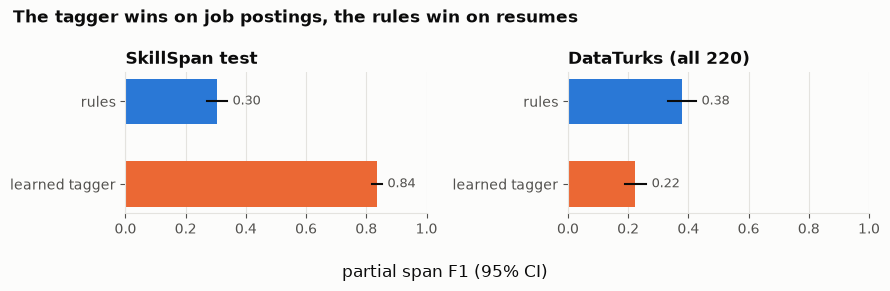

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(9, 2.8), sharex=True)
corpora = [("SkillSpan test", {s: r["skillspan"]["test"][s]["union"] for s in ("rules", "ner")}),
           ("DataTurks (all 220)", r["dataturks"]["all"])]
for ax, (title, block) in zip(axes, corpora):
    for i, (system, color) in enumerate(zip(("rules", "ner"), reporting.SERIES)):
        f1 = block[system]["partial"]["f1"]; lo, hi = block[system]["partial"]["f1_ci"]
        ax.barh(i, f1, color=color, height=0.55)
        ax.plot([lo, hi], [i, i], color=reporting.TEXT, linewidth=1.5)
        ax.annotate(f"{f1:.2f}", (hi, i), xytext=(4, 0), textcoords="offset points", va="center",
                    color=reporting.TEXT_2, fontsize=9)
    ax.set_yticks([0, 1], ["rules", "learned tagger"])
    ax.set_title(title)
    ax.grid(axis="y", visible=False)
    ax.set_xlim(0, 1)
axes[0].invert_yaxis(); axes[1].invert_yaxis()
fig.supxlabel("partial span F1 (95% CI)")
fig.suptitle("The tagger wins on job postings, the rules win on resumes", x=0.02, ha="left", fontweight="bold")
plt.tight_layout()

## Paired deltas, tagger − rules

In [4]:
pd.DataFrame([
    {"corpus": "SkillSpan test", "scope": scope,
     "strict Δ": r["skillspan"]["test"]["ner_minus_rules"][scope]["strict"],
     "partial Δ": r["skillspan"]["test"]["ner_minus_rules"][scope]["partial"]}
    for scope in ("union", "skill", "knowledge")])

,corpus,scope,strict Δ,partial Δ
0,SkillSpan test,union,"{'f1_delta': 0.286, 'f1_delta_ci': [0.2563, 0....","{'f1_delta': 0.532, 'f1_delta_ci': [0.4987, 0...."
1,SkillSpan test,skill,"{'f1_delta': 0.2717, 'f1_delta_ci': [0.247, 0....","{'f1_delta': 0.5014, 'f1_delta_ci': [0.4691, 0..."
2,SkillSpan test,knowledge,"{'f1_delta': 0.0321, 'f1_delta_ci': [-0.0057, ...","{'f1_delta': 0.1144, 'f1_delta_ci': [0.074, 0...."


## Normalisation: mapping a phrase to its canonical skill

Held-out ESCO alternative labels mapped back to their concept (top-1 accuracy).

In [5]:
n = r["normalisation"]
pd.DataFrame([{"setting": k, "string": f"{v['methods']['string']['top1']:.3f}",
               "SBERT": f"{v['methods']['sbert']['top1']:.3f}",
               "SBERT − string": f"{v['sbert_minus_string']['delta']:+.3f} {v['sbert_minus_string']['delta_ci']}"}
              for k, v in n.items() if isinstance(v, dict) and "methods" in v])

,setting,string,SBERT,SBERT − string
0,ict_preferred,0.602,0.766,"+0.164 [0.138, 0.191]"
1,ict_aliases,0.734,0.864,"+0.130 [0.105, 0.155]"
2,all_esco_preferred,0.582,0.782,"+0.200 [0.17, 0.231]"


**Reading (D49).** On job postings the tagger is clearly better: SkillSpan union strict F1
0.523 against 0.237, because the vocabulary cannot name soft-skill phrases. On resumes the
rules matcher is better: DataTurks partial F1 0.380 against 0.224, because the tagger learned
SkillSpan's convention of tagging requirement phrases. So the pipeline splits by role. The
tagger adds free-text JD requirements, and the rules matcher does every CV-side exact match.
Neither reaches the provisional S3 bar of 0.85 strict F1.